# Customer Location, Seller Distance, and Review Score Analysis

This notebook is structured in two phases:
1. Analyze customer location, seller distance, and observed review score only.
2. Extend analysis by including expected review score (`expected_review_A`).

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)

candidate_paths = [
    Path('../../datasets/processed/olist_reviews_with_preds.csv'),
    Path('brazil_ecommerce/datasets/processed/olist_reviews_with_preds.csv'),
    Path('datasets/processed/olist_reviews_with_preds.csv'),
]

data_path = None
for p in candidate_paths:
    if p.exists(): 
        data_path = p.resolve()
        break

if data_path is None:
    raise FileNotFoundError('Could not locate olist_reviews_with_preds.csv from current working directory.')

print(f'Using dataset: {data_path}')

Using dataset: C:\Users\Admin\OneDrive\Desktop\Coursework\semester 6\AML Business\Project\AMLB\brazil_ecommerce\datasets\processed\olist_reviews_with_preds.csv


In [32]:
columns_needed = [
    'order_id',
    'customer_state',
    'seller_state',
    'customer_lat',
    'customer_lng',
    'seller_lat',
    'seller_lng',
    'distance_km',
    'review_score',
    'expected_review_A',
    'product_category_name',
    'delivery_delay_days',
    'freight_ratio',
]

df = pd.read_csv(data_path, usecols=columns_needed)
print('Shape:', df.shape)
df.head()

Shape: (94009, 13)


,order_id,review_score,product_category_name,seller_state,customer_state,customer_lat,customer_lng,seller_lat,seller_lng,distance_km,delivery_delay_days,freight_ratio,expected_review_A
0,e481f51cbdc54678b7cc49136f2d6af7,4.0,utilidades_domesticas,SP,SP,-23.576170,-46.587276,-23.681180,-46.444127,18.681711,-7.0,0.281381,4.284404
1,53cdb2fc8bc7dce0b6741e2150273451,4.0,perfumaria,SP,BA,-12.126651,-45.008162,-19.807013,-43.980966,861.035367,-6.0,0.190142,4.395447
2,47770eb9100c2d0c44946d9cf07ec65d,5.0,automotivo,SP,GO,-16.744472,-48.514624,-21.364020,-48.228831,514.547140,-17.0,0.119453,4.489018
3,949d5b44dbf5de918fe9c16f97b45f8a,5.0,pet_shop,MG,RN,-5.774611,-35.273916,-19.836541,-43.921855,1821.802656,-13.0,0.591304,4.409170
4,ad21c59c0840e6cb83a9ceb5573f8159,5.0,papelaria,SP,SP,-23.675316,-46.515116,-23.545033,-46.261847,29.593095,-10.0,0.417225,4.456605


## Phase 1: Without Expected Review Score

Focus only on observed `review_score` with customer-seller distance and location features.

In [33]:
base_cols = ['distance_km', 'review_score', 'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'customer_state', 'seller_state']
df_base = df.dropna(subset=base_cols).copy()

print('Rows usable for Phase 1:', len(df_base))
display(df_base[['distance_km', 'review_score']].describe())

missing_pct = (df[base_cols].isna().mean() * 100).sort_values(ascending=False).round(2)
display(missing_pct.to_frame('missing_pct'))

Rows usable for Phase 1: 94009


,distance_km,review_score
count,94009.000000,94009.000000
mean,600.980157,4.157593
std,593.958801,1.282050
min,0.000000,1.000000
25%,186.433319,4.000000
50%,434.273339,5.000000
75%,798.700433,5.000000
max,8677.859564,5.000000


,missing_pct
distance_km,0.0
review_score,0.0
customer_lat,0.0
customer_lng,0.0
seller_lat,0.0
seller_lng,0.0
customer_state,0.0
seller_state,0.0


Yes, there are review scores with decimal values.


,count
review_score,
1.500000,8
2.500000,28
3.333333,1
3.500000,23
4.333333,1
4.500000,52


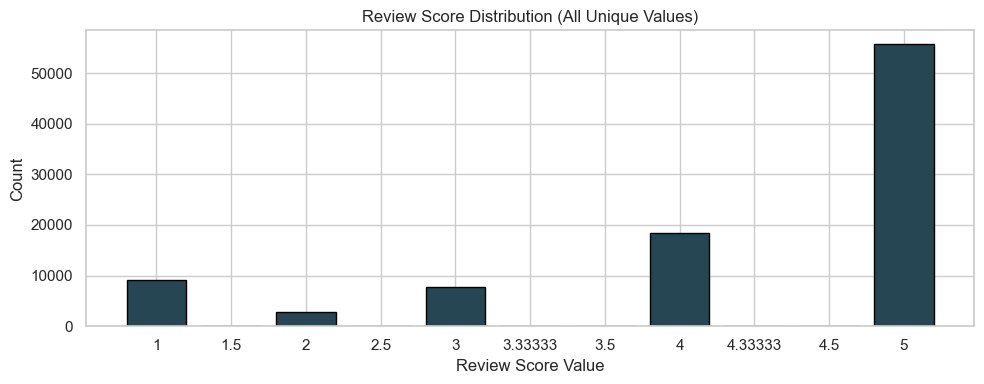

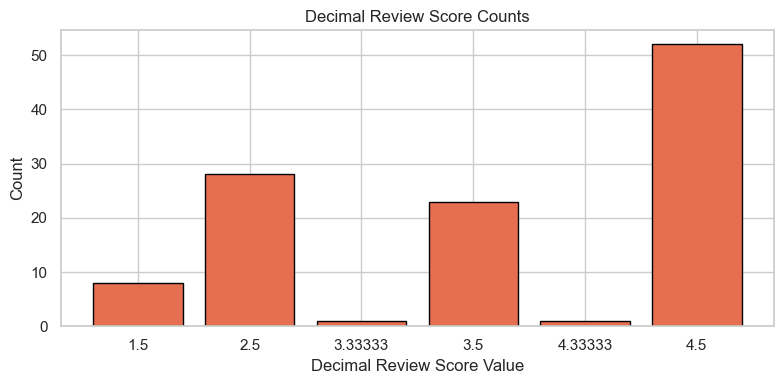

In [34]:
has_decimal_scores = (~np.isclose(df['review_score'] % 1, 0)).any()

if has_decimal_scores:
    print("Yes, there are review scores with decimal values.")
    decimal_values = (
        df.loc[~np.isclose(df['review_score'] % 1, 0), 'review_score']
        .value_counts()
        .sort_index()
    )
    display(decimal_values.rename('count').to_frame())
else:
    print("No, review scores are whole numbers (stored as float), e.g., 1.0 to 5.0.")

# Plot 1: all unique review scores (force categorical labels so decimals are not hidden)
score_counts = df['review_score'].value_counts().sort_index()
labels_all = [f'{v:g}' for v in score_counts.index]

plt.figure(figsize=(10, 4))
ax = plt.bar(labels_all, score_counts.values, color='#264653', edgecolor='black')
plt.title('Review Score Distribution (All Unique Values)')
plt.xlabel('Review Score Value')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Plot 2: decimal-only scores for visibility
if has_decimal_scores:
    labels_dec = [f'{v:g}' for v in decimal_values.index]
    plt.figure(figsize=(8, 4))
    plt.bar(labels_dec, decimal_values.values, color='#e76f51', edgecolor='black')
    plt.title('Decimal Review Score Counts')
    plt.xlabel('Decimal Review Score Value')
    plt.ylabel('Count')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

99th percentile distance: 2483.39 km
Rows kept: 93,068 / 94,009


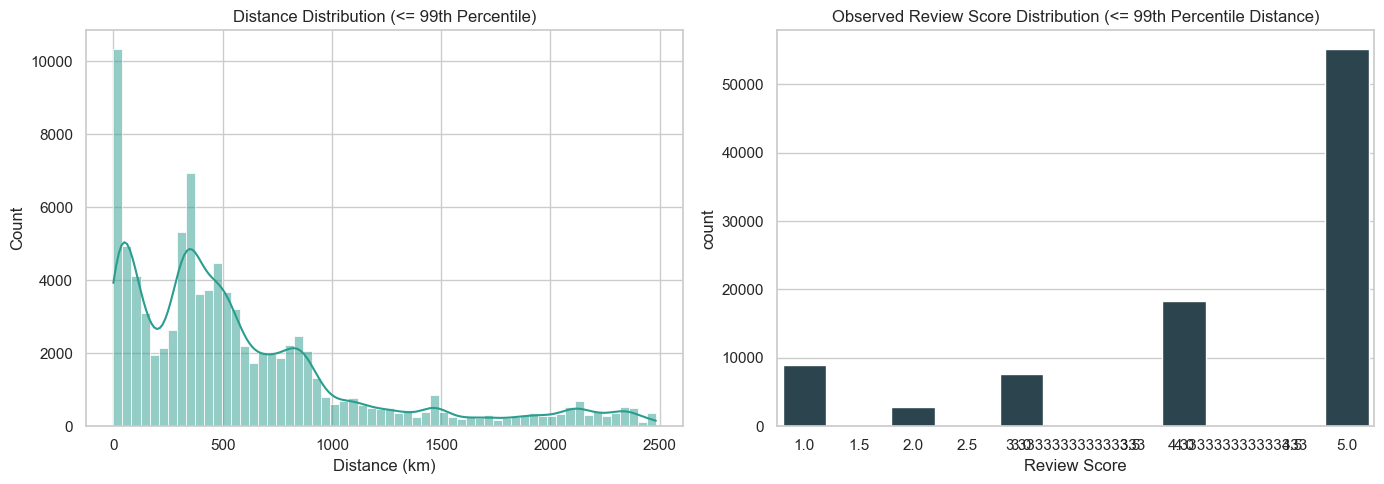

In [35]:
p99_distance = df_base['distance_km'].quantile(0.99)
df_base_p99 = df_base[df_base['distance_km'] <= p99_distance].copy()

print(f'99th percentile distance: {p99_distance:.2f} km')
print(f'Rows kept: {len(df_base_p99):,} / {len(df_base):,}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_base_p99['distance_km'], bins=60, kde=True, ax=axes[0], color='#2a9d8f')
axes[0].set_title('Distance Distribution (<= 99th Percentile)')
axes[0].set_xlabel('Distance (km)')

sns.countplot(x='review_score', data=df_base_p99, ax=axes[1], color='#264653')
axes[1].set_title('Observed Review Score Distribution (<= 99th Percentile Distance)')
axes[1].set_xlabel('Review Score')

plt.tight_layout()
plt.show()

,count,mean,median,std
distance_band,,,,
0-50,11464,4.285,5.0,1.184
50-200,12647,4.288,5.0,1.179
200-500,29589,4.155,5.0,1.294
500-1000,25270,4.115,5.0,1.302
1000-2000,9549,4.053,5.0,1.340
2000+,5490,3.979,5.0,1.391


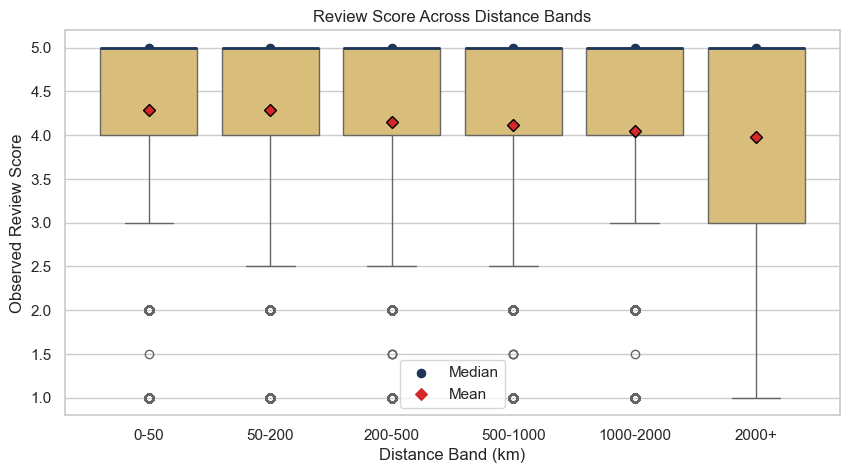

In [36]:
distance_bins = [0, 50, 200, 500, 1000, 2000, np.inf]
distance_labels = ['0-50', '50-200', '200-500', '500-1000', '1000-2000', '2000+']

df_base['distance_band'] = pd.cut(
    df_base['distance_km'],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True
)

band_stats = (
    df_base.groupby('distance_band', observed=True)['review_score']
    .agg(['count', 'mean', 'median', 'std'])
    .reindex(distance_labels)
    .round(3)
)
display(band_stats)

plt.figure(figsize=(10, 5))
ax = sns.boxplot(
    data=df_base,
    x='distance_band',
    y='review_score',
    order=distance_labels,
    color='#e9c46a',
    showmeans=True,
    meanprops={
        'marker': 'D',
        'markerfacecolor': '#d62828',
        'markeredgecolor': 'black',
        'markersize': 6
    },
    medianprops={
        'color': '#1d3557',
        'linewidth': 2
    }
)

# Explicit median markers (in addition to median line in box)
ax.scatter(
    range(len(distance_labels)),
    band_stats['median'].values,
    color='#1d3557',
    marker='o',
    s=35,
    label='Median'
)

# Explicit mean markers (same values as boxplot mean markers)
ax.scatter(
    range(len(distance_labels)),
    band_stats['mean'].values,
    color='#d62828',
    marker='D',
    s=35,
    label='Mean'
)

plt.title('Review Score Across Distance Bands')
plt.xlabel('Distance Band (km)')
plt.ylabel('Observed Review Score')
plt.legend()
plt.show()

Spearman correlation (distance vs review_score): -0.0653


,orders,avg_distance_km,avg_review
customer_state,,,
SP,39630,250.155,4.250
PR,4809,486.899,4.238
MG,11082,534.111,4.190
RS,5232,864.014,4.187
MS,688,843.747,4.167
RO,234,2227.575,4.162
MT,863,1352.912,4.156
RN,463,2103.525,4.144
TO,268,1488.137,4.142


,orders,avg_distance_km,avg_review
customer_state,,,
TO,268,1488.137,4.142
SC,3453,572.214,4.140
DF,1877,836.030,4.123
GO,1887,777.709,4.104
PE,1557,1970.322,4.088
ES,1941,805.844,4.078
PB,498,2091.261,4.052
PI,461,1955.507,3.991
RJ,11985,489.864,3.966


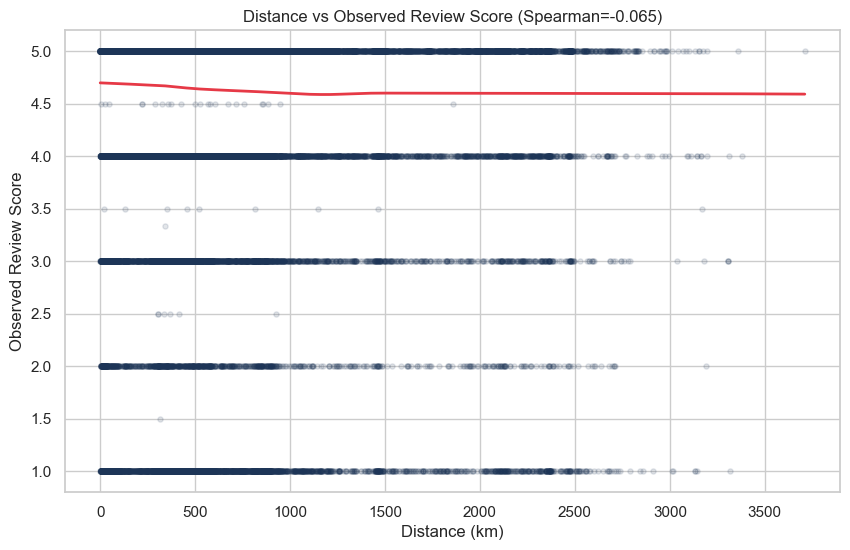

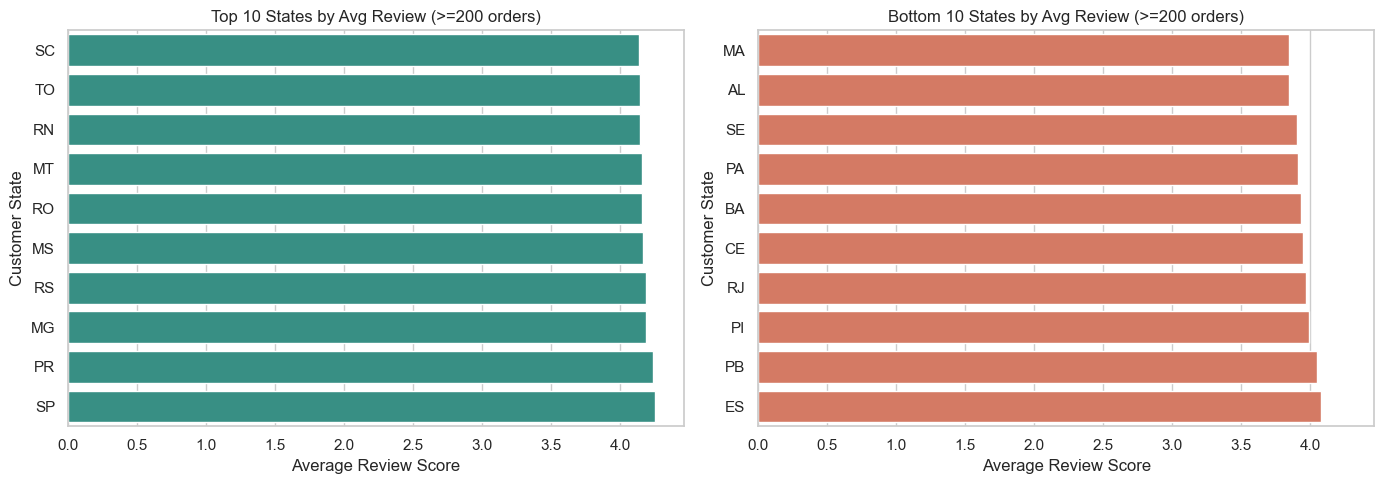

In [37]:
corr_value = df_base[['distance_km', 'review_score']].corr(method='spearman').iloc[0, 1]
print(f'Spearman correlation (distance vs review_score): {corr_value:.4f}')

state_summary = (
    df_base.groupby('customer_state', observed=True)
    .agg(
        orders=('order_id', 'count'),
        avg_distance_km=('distance_km', 'mean'),
        avg_review=('review_score', 'mean')
    )
    .query('orders >= 200')
    .sort_values('avg_review', ascending=False)
    .round(3)
)

display(state_summary.head(15))
display(state_summary.tail(15))

# 1) Distance vs review score (sampled) with trend line
plot_df = df_base.sample(min(30000, len(df_base)), random_state=42)

plt.figure(figsize=(10, 6))
sns.regplot(
    data=plot_df,
    x='distance_km',
    y='review_score',
    scatter_kws={'alpha': 0.12, 's': 14, 'color': '#1d3557'},
    line_kws={'color': '#e63946', 'linewidth': 2},
    lowess=True
)
plt.title(f'Distance vs Observed Review Score (Spearman={corr_value:.3f})')
plt.xlabel('Distance (km)')
plt.ylabel('Observed Review Score')
plt.show()

# 2) State-level average review (best vs worst)
top_states = state_summary.head(10).sort_values('avg_review')
bottom_states = state_summary.tail(10).sort_values('avg_review')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

sns.barplot(data=top_states, x='avg_review', y=top_states.index, color='#2a9d8f', ax=axes[0])
axes[0].set_title('Top 10 States by Avg Review (>=200 orders)')
axes[0].set_xlabel('Average Review Score')
axes[0].set_ylabel('Customer State')

sns.barplot(data=bottom_states, x='avg_review', y=bottom_states.index, color='#e76f51', ax=axes[1])
axes[1].set_title('Bottom 10 States by Avg Review (>=200 orders)')
axes[1].set_xlabel('Average Review Score')
axes[1].set_ylabel('Customer State')

plt.tight_layout()
plt.show()

## Phase 2: Add Expected Review Score

Now include `expected_review_A` and measure the gap between observed and expected values.

In [38]:
df_exp = df.dropna(subset=['distance_km', 'review_score', 'expected_review_A']).copy()
df_exp['review_gap'] = df_exp['review_score'] - df_exp['expected_review_A']
df_exp['abs_review_gap'] = df_exp['review_gap'].abs()

print('Rows usable for Phase 2:', len(df_exp))
display(df_exp[['review_score', 'expected_review_A', 'review_gap', 'abs_review_gap']].describe().round(3))

Rows usable for Phase 2: 94009


,review_score,expected_review_A,review_gap,abs_review_gap
count,94009.000,94009.000,94009.000,94009.000
mean,4.158,4.160,-0.003,0.845
std,1.282,0.586,1.095,0.696
min,1.000,1.117,-3.685,0.000
25%,4.000,4.176,-0.438,0.495
50%,5.000,4.359,0.514,0.600
75%,5.000,4.452,0.640,0.869
max,5.000,4.759,3.609,3.685


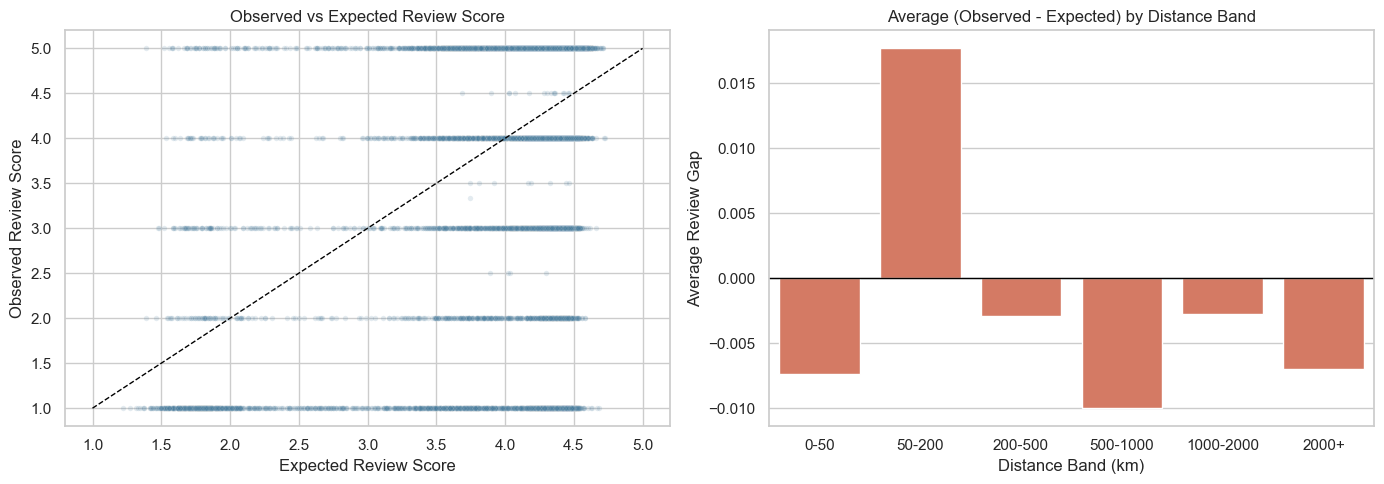

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df_exp.sample(min(20000, len(df_exp)), random_state=42),
    x='expected_review_A',
    y='review_score',
    alpha=0.15,
    s=15,
    color='#457b9d',
    ax=axes[0]
)
axes[0].plot([1, 5], [1, 5], linestyle='--', color='black', linewidth=1)
axes[0].set_title('Observed vs Expected Review Score')
axes[0].set_xlabel('Expected Review Score')
axes[0].set_ylabel('Observed Review Score')

df_exp['distance_band'] = pd.cut(df_exp['distance_km'], bins=distance_bins, labels=distance_labels, include_lowest=True)
gap_by_band = df_exp.groupby('distance_band', observed=True)['review_gap'].mean().reindex(distance_labels)
sns.barplot(x=gap_by_band.index, y=gap_by_band.values, color='#e76f51', ax=axes[1])
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_title('Average (Observed - Expected) by Distance Band')
axes[1].set_xlabel('Distance Band (km)')
axes[1].set_ylabel('Average Review Gap')

plt.tight_layout()
plt.show()

States where observed is lower than expected (most negative gap):


,orders,avg_distance_km,avg_observed,avg_expected,avg_gap
customer_state,,,,,
DF,1877,836.030,4.123,4.180,-0.058
BA,3170,1344.150,3.931,3.984,-0.053
MA,699,2103.069,3.846,3.896,-0.050
PI,461,1955.507,3.991,4.016,-0.025
RJ,11985,489.864,3.966,3.988,-0.023
MG,11082,534.111,4.190,4.207,-0.017
GO,1887,777.709,4.104,4.115,-0.011
PA,914,2292.663,3.908,3.918,-0.010
SP,39630,250.155,4.250,4.258,-0.008


States where observed is higher than expected (most positive gap):


,orders,avg_distance_km,avg_observed,avg_expected,avg_gap
customer_state,,,,,
SP,39630,250.155,4.250,4.258,-0.008
SE,331,1649.631,3.903,3.911,-0.008
ES,1941,805.844,4.078,4.076,0.003
CE,1253,2183.757,3.951,3.945,0.005
PE,1557,1970.322,4.088,4.076,0.012
RO,234,2227.575,4.162,4.144,0.018
PR,4809,486.899,4.238,4.219,0.019
PB,498,2091.261,4.052,4.027,0.026
SC,3453,572.214,4.140,4.090,0.051


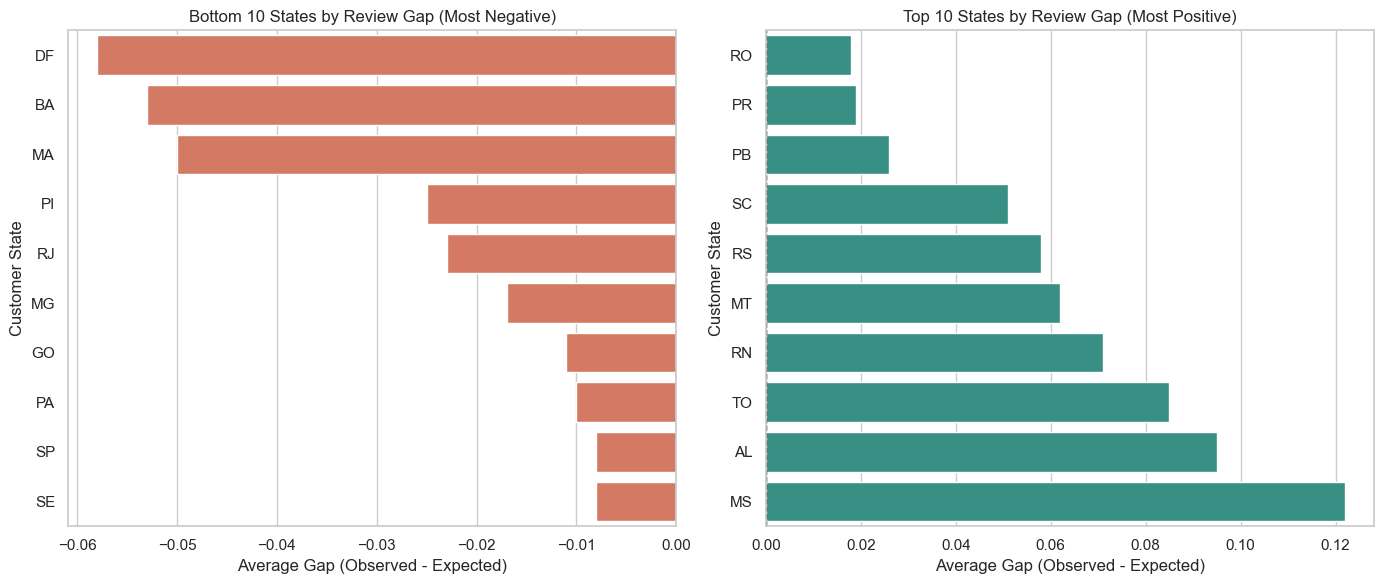

In [40]:
state_gap = (
    df_exp.groupby('customer_state', observed=True)
    .agg(
        orders=('order_id', 'count'),
        avg_distance_km=('distance_km', 'mean'),
        avg_observed=('review_score', 'mean'),
        avg_expected=('expected_review_A', 'mean'),
        avg_gap=('review_gap', 'mean')
    )
    .query('orders >= 200')
    .sort_values('avg_gap')
    .round(3)
)

print('States where observed is lower than expected (most negative gap):')
display(state_gap.head(15))

print('States where observed is higher than expected (most positive gap):')
display(state_gap.tail(15))

# Visualize the gap analysis by state
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bottom 10 states (most negative gap)
bottom_gap = state_gap.head(10).sort_values('avg_gap')
sns.barplot(data=bottom_gap, x='avg_gap', y=bottom_gap.index, color='#e76f51', ax=axes[0])
axes[0].set_title('Bottom 10 States by Review Gap (Most Negative)')
axes[0].set_xlabel('Average Gap (Observed - Expected)')
axes[0].set_ylabel('Customer State')
axes[0].axvline(0, color='black', linewidth=1, linestyle='--')

# Top 10 states (most positive gap)
top_gap = state_gap.tail(10).sort_values('avg_gap')
sns.barplot(data=top_gap, x='avg_gap', y=top_gap.index, color='#2a9d8f', ax=axes[1])
axes[1].set_title('Top 10 States by Review Gap (Most Positive)')
axes[1].set_xlabel('Average Gap (Observed - Expected)')
axes[1].set_ylabel('Customer State')
axes[1].axvline(0, color='black', linewidth=1, linestyle='--')

plt.tight_layout()
plt.show()

## Extension 3: Model Review Gap with Distance, Delay, and Freight Ratio

Fit a baseline linear model to estimate review gap from operational variables.

Linear model performance on holdout set:
R^2:  0.0002
MAE:  0.8343


,feature,coefficient
2,freight_ratio,0.008320
1,delivery_delay_days,-0.000987
0,distance_km,-0.000004


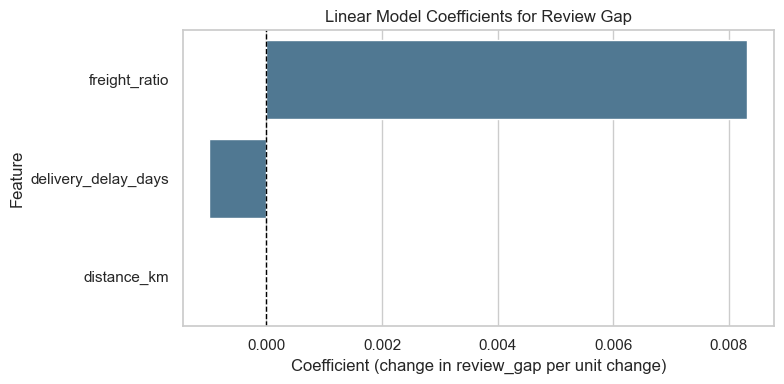

In [41]:
model_df = df_exp.dropna(subset=['distance_km', 'delivery_delay_days', 'freight_ratio', 'review_gap']).copy()

X = model_df[['distance_km', 'delivery_delay_days', 'freight_ratio']]
y = model_df['review_gap']

n_train = int(len(model_df) * 0.8)
train_idx = model_df.sample(n=n_train, random_state=42).index
test_idx = model_df.index.difference(train_idx)

X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_test, y_test = X.loc[test_idx], y.loc[test_idx]

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)
pred_test = lin_model.predict(X_test)

print('Linear model performance on holdout set:')
print(f'R^2:  {r2_score(y_test, pred_test):.4f}')
print(f'MAE:  {mean_absolute_error(y_test, pred_test):.4f}')

coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': lin_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=coef_df, x='coefficient', y='feature', color='#457b9d')
plt.title('Linear Model Coefficients for Review Gap')
plt.xlabel('Coefficient (change in review_gap per unit change)')
plt.ylabel('Feature')
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.tight_layout()
plt.show()

## Extension 2: Seller State and Product Category Segmentation

Identify where distance appears to hurt review score most by segmenting on seller state and product category.

,seller_state,product_category_name,n_orders,avg_distance_km,avg_review,distance_review_penalty
8,MA,beleza_saude,382,1945.657,4.029,1889.631
38,PR,consoles_games,137,1134.714,3.810,1350.061
37,PR,cama_mesa_banho,99,874.008,3.495,1315.426
83,SC,automotivo,163,942.722,3.687,1237.684
31,PE,informatica_acessorios,336,1565.149,4.324,1057.407
1,BA,telefonia,257,1096.978,4.109,977.463
3,DF,cool_stuff,73,872.179,3.904,955.812
39,PR,construcao_ferramentas_construcao,66,721.659,3.689,945.811
0,BA,pcs,141,1226.935,4.241,931.078
30,MT,perfumaria,54,1576.625,4.426,905.099


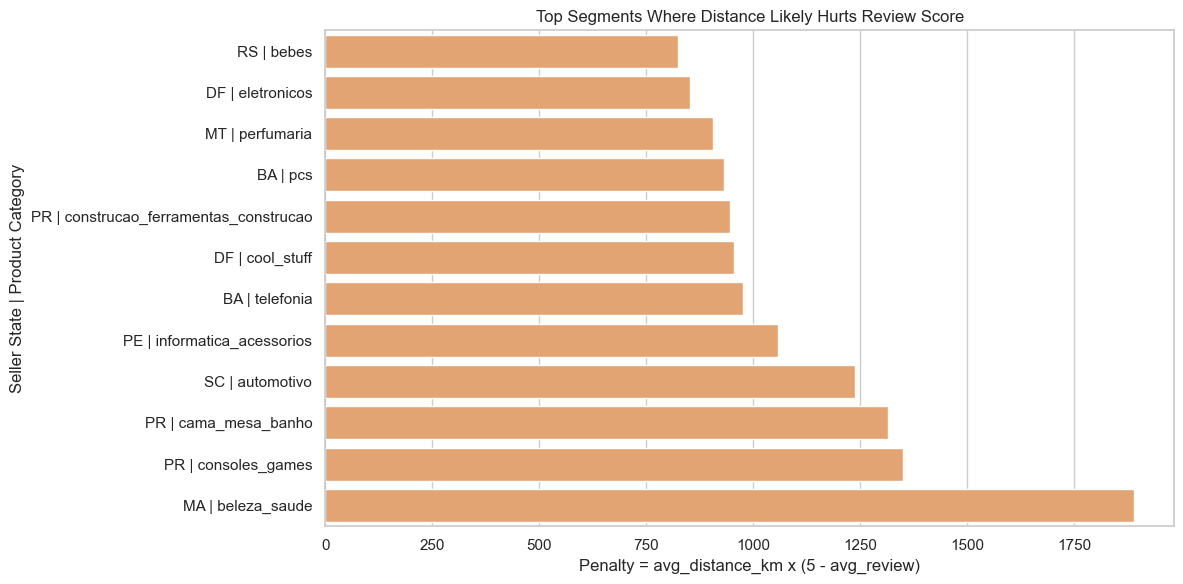

In [42]:
seg_df = df.dropna(subset=['seller_state', 'product_category_name', 'distance_km', 'review_score']).copy()

seg_summary = (
    seg_df.groupby(['seller_state', 'product_category_name'], observed=True)
    .agg(
        n_orders=('order_id', 'count'),
        avg_distance_km=('distance_km', 'mean'),
        avg_review=('review_score', 'mean')
    )
    .query('n_orders >= 50')
    .reset_index()
)

# Penalize segments with both long distance and low score.
seg_summary['distance_review_penalty'] = seg_summary['avg_distance_km'] * (5 - seg_summary['avg_review'])

worst_segments = seg_summary.sort_values('distance_review_penalty', ascending=False).head(20)
display(worst_segments[['seller_state', 'product_category_name', 'n_orders', 'avg_distance_km', 'avg_review', 'distance_review_penalty']].round(3))

plot_segments = worst_segments.head(12).sort_values('distance_review_penalty', ascending=True)
plot_segments['segment'] = plot_segments['seller_state'] + ' | ' + plot_segments['product_category_name']

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_segments, x='distance_review_penalty', y='segment', color='#f4a261')
plt.title('Top Segments Where Distance Likely Hurts Review Score')
plt.xlabel('Penalty = avg_distance_km x (5 - avg_review)')
plt.ylabel('Seller State | Product Category')
plt.tight_layout()
plt.show()

## Extension 1: Statistical Test Across Distance Bands

Use Kruskal-Wallis to test whether review score distributions differ by distance band.

In [45]:
kw_df = df_base.dropna(subset=['distance_band', 'review_score']).copy()

groups = [
    kw_df.loc[kw_df['distance_band'] == band, 'review_score'].values
    for band in distance_labels
    if (kw_df['distance_band'] == band).sum() > 0
]
# Kruskal-Wallis test: non-parametric test for differences across distance bands
# H0 (null): Review score distributions are the same across all distance bands
# H1 (alternative): At least one distance band has a different review score distribution

print('Kruskal-Wallis Test')
print('H0 (null hypothesis): Review score distributions are identical across distance bands.')
print('H1 (alternative hypothesis): At least one distance band has a different distribution.')
print()
kw_stat, kw_p = kruskal(*groups)
print(f'Kruskal-Wallis H statistic: {kw_stat:.4f}')
print(f'p-value: {kw_p:.6g}')

if kw_p < 0.05:
    print('Result: Review score distributions are significantly different across distance bands (reject H0).')
else:
    print('Result: No statistically significant difference detected across distance bands (fail to reject H0).')

Kruskal-Wallis Test
H0 (null hypothesis): Review score distributions are identical across distance bands.
H1 (alternative hypothesis): At least one distance band has a different distribution.

Kruskal-Wallis H statistic: 442.0465
p-value: 2.5515e-93
Result: Review score distributions are significantly different across distance bands (reject H0).


## Completed Extensions

- Kruskal-Wallis test across distance bands is now included.
- Seller state x product category segmentation is now included.
- Review gap modeling with distance, delivery delay, and freight ratio is now included.

You can rerun the notebook top-to-bottom to regenerate all outputs from a clean state.